# Régression logistique et classification : orages à Nosy Be

**Objectif :** prédire `Storm_NosyBe_1h`, c'est-à-dire la présence ou l'absence d'un orage à Nosy Be à une échéance de **1 heure**.

Ce notebook accompagne le cours sur la **régression logistique** et les **métriques de classification**.

Nous allons :

- explorer le jeu de données ;
- vérifier la qualité des données ;
- préparer simplement les variables explicatives ;
- entraîner une régression logistique ;
- transformer les probabilités en classes ;
- construire une matrice de confusion ;
- calculer accuracy, precision, recall, F1-score, ROC-AUC et Average Precision ;
- étudier l'effet du seuil de classification ;
- traiter le déséquilibre entre les classes ;
- interpréter les coefficients du modèle.

> À ce stade, nous gardons les variables temporelles sous leur forme brute, sans encodage cyclique.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

RANDOM_STATE = 42

## 1. Charger les données

In [2]:
data_path = Path("Orage_NosyBe.csv")

if not data_path.exists():
    data_path = Path("/mnt/data/Orage_NosyBe.csv")

df = pd.read_csv(data_path)

print(f"Nombre de lignes : {df.shape[0]:,}")
print(f"Nombre de colonnes : {df.shape[1]}")
df.head()

Nombre de lignes : 51,082
Nombre de colonnes : 12


,year,month,day,hour,minute,lat,lon,intensity,size,distance,Storm_NosyBe_1h,Storm_NosyBe_3h
0,2004,1,19,10,30,-13.6126,48.2281,468.0,1422.0,10.44,0,1
1,2004,1,19,10,45,-13.7039,48.2598,488.0,1881.0,13.34,0,1
2,2004,1,19,11,0,-13.7953,48.2918,424.0,1746.0,16.28,0,1
3,2004,1,19,11,15,-14.2190,48.3387,485.0,4167.0,30.41,0,1
4,2004,1,19,11,30,-13.2851,49.2745,155.0,207.0,19.10,0,1


## 2. Comprendre les variables

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51082 entries, 0 to 51081
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   year             51082 non-null  int64  
 1   month            51082 non-null  int64  
 2   day              51082 non-null  int64  
 3   hour             51082 non-null  int64  
 4   minute           51082 non-null  int64  
 5   lat              51077 non-null  float64
 6   lon              51077 non-null  float64
 7   intensity        51074 non-null  float64
 8   size             51074 non-null  float64
 9   distance         51074 non-null  float64
 10  Storm_NosyBe_1h  51082 non-null  int64  
 11  Storm_NosyBe_3h  51082 non-null  int64  
dtypes: float64(5), int64(7)
memory usage: 4.7 MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,51082.0,2011.761873,4.645658,2004.0000,2008.0000,2012.0000,2016.0000,2019.00
month,51082.0,4.760268,4.311409,1.0000,2.0000,3.0000,11.0000,13.00
day,51082.0,15.964684,8.710683,1.0000,8.0000,16.0000,24.0000,31.00
hour,51082.0,13.619984,5.576657,0.0000,11.0000,14.0000,17.0000,27.00
minute,51082.0,22.507635,16.763317,0.0000,15.0000,30.0000,30.0000,45.00
lat,51077.0,-13.628534,0.783011,-14.9995,-14.0810,-13.5401,-13.1697,95.00
lon,51077.0,48.782367,0.976579,47.5003,48.1783,48.7577,49.3077,190.00
intensity,51074.0,210.811450,86.581297,87.0000,144.0000,190.0000,258.0000,928.00
size,51074.0,3937.339116,5696.202548,45.0000,621.0000,1773.0000,4770.0000,85266.00
distance,51074.0,24.689673,13.422112,0.0000,14.3200,21.9300,33.8400,61.74


Le jeu de données contient notamment :

- `year`, `month`, `day`, `hour`, `minute` : date et heure ;
- `lat`, `lon` : position ;
- `intensity` : intensité ;
- `size` : taille ;
- `distance` : distance par rapport à Nosy Be ;
- `Storm_NosyBe_1h` : **variable cible** à 1 heure ;
- `Storm_NosyBe_3h` : autre cible, qui ne sera pas utilisée comme prédicteur.

La variable cible est binaire :

- `0` : pas d'orage ;
- `1` : orage.

## 3. Vérifier les valeurs manquantes et la qualité des données

In [5]:
missing = df.isna().sum().sort_values(ascending=False)
missing[missing > 0]

size         8
distance     8
intensity    8
lat          5
lon          5
dtype: int64

In [6]:
print("Valeurs de month :", sorted(df["month"].unique()))
print("Valeurs de hour  :", sorted(df["hour"].unique()))
print("Valeurs de minute:", sorted(df["minute"].unique()))

Valeurs de month : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(11), np.int64(12), np.int64(13)]
Valeurs de hour  : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(27)]
Valeurs de minute: [np.int64(0), np.int64(15), np.int64(30), np.int64(45)]


In [7]:
invalid_time = (df["month"] < 1) | (df["month"] > 12) | (df["hour"] < 0) | (df["hour"] > 23)

df.loc[invalid_time, ["year", "month", "day", "hour", "minute"]]

,year,month,day,hour,minute
20985,2010,12,2,27,30
49417,2019,13,14,16,15


Deux lignes présentent des valeurs temporelles impossibles. Pour cet exercice, nous les retirons.

Les quelques valeurs manquantes dans les variables explicatives seront remplacées par la **médiane** dans le pipeline.

In [8]:
df = df.loc[~invalid_time].copy()

print(f"Nombre de lignes après nettoyage : {len(df):,}")

Nombre de lignes après nettoyage : 51,080


## 4. Examiner la variable cible

In [9]:
target = "Storm_NosyBe_1h"

class_counts = df[target].value_counts().sort_index()
class_percent = df[target].value_counts(normalize=True).sort_index() * 100

target_summary = pd.DataFrame({
    "Nombre": class_counts,
    "Pourcentage (%)": class_percent
})

target_summary

,Nombre,Pourcentage (%)
Storm_NosyBe_1h,,
0,47833,93.643305
1,3247,6.356695


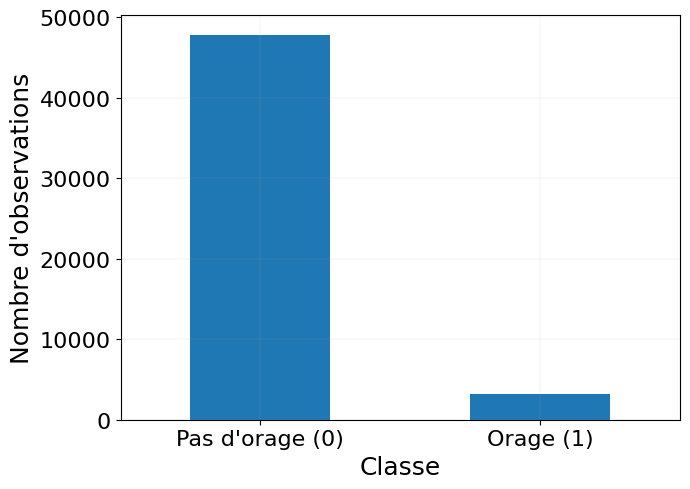

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))

class_counts.plot(kind="bar", ax=ax)

plt.xticks([0, 1], ["Pas d'orage (0)", "Orage (1)"], rotation=0, fontsize=16)
plt.yticks(fontsize=16)

plt.xlabel("Classe", fontsize=18)
plt.ylabel("Nombre d'observations", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.tight_layout()
plt.show()

La classe `1` est rare par rapport à la classe `0`.

Il s'agit donc d'un **problème de classification déséquilibré**.

Un modèle qui prédit toujours `0` pourrait obtenir une accuracy élevée tout en étant incapable de détecter les orages.

## 5. Définir les entrées `X` et la cible `y`

In [11]:
features = [
    "year",
    "month",
    "day",
    "hour",
    "minute",
    "lat",
    "lon",
    "intensity",
    "size",
    "distance"
]

X = df[features].copy()
y = df[target].copy()

print("Variables utilisées :")
print(features)

print()
print("Forme de X :", X.shape)
print("Forme de y :", y.shape)

Variables utilisées :
['year', 'month', 'day', 'hour', 'minute', 'lat', 'lon', 'intensity', 'size', 'distance']

Forme de X : (51080, 10)
Forme de y : (51080,)


Les variables temporelles sont gardées ici sous leur forme simple : `year`, `month`, `day`, `hour` et `minute`.

`Storm_NosyBe_3h` n'est pas utilisé comme variable explicative afin de ne pas introduire une autre cible dans les entrées du modèle.

## 6. Séparer les données d'entraînement et de test

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"Entraînement : {len(X_train):,} observations")
print(f"Test         : {len(X_test):,} observations")

print()
print("Proportion d'orages dans l'entraînement :", round(y_train.mean(), 4))
print("Proportion d'orages dans le test         :", round(y_test.mean(), 4))

Entraînement : 40,864 observations
Test         : 10,216 observations

Proportion d'orages dans l'entraînement : 0.0636
Proportion d'orages dans le test         : 0.0635


L'option `stratify=y` permet de conserver approximativement la même proportion d'orages dans les ensembles d'entraînement et de test.

## 7. Construire une régression logistique

La régression logistique calcule d'abord un score linéaire :

\[
z = b + w_1x_1 + w_2x_2 + \cdots + w_nx_n
\]

Puis elle applique la fonction sigmoïde :

\[
p = \frac{1}{1 + e^{-z}}
\]

La sortie `p` est comprise entre 0 et 1 et peut être interprétée comme une probabilité.

In [13]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

model.fit(X_train, y_train)

print("Modèle entraîné.")

Modèle entraîné.


## 8. Obtenir les probabilités

In [14]:
y_prob = model.predict_proba(X_test)[:, 1]

probabilities = pd.DataFrame({
    "Observation": y_test.to_numpy(),
    "Probabilite_orage": y_prob
})

probabilities.head(10)

,Observation,Probabilite_orage
0,0,0.043556
1,0,0.037436
2,0,0.066079
3,0,0.010119
4,1,0.020738
5,1,0.012611
6,0,0.002065
7,0,0.001884
8,0,0.001010
9,0,0.003843


La régression logistique produit une **probabilité**.

Pour obtenir une classe `0` ou `1`, il faut choisir un **seuil de classification**.

Avec un seuil de 0.5 :

$
\hat{y} =
\begin{cases}
1 & \text{si } p \geq 0.5 \\
0 & \text{si } p < 0.5
\end{cases}
$

In [15]:
threshold = 0.5
y_pred = (y_prob >= threshold).astype(int)

pd.DataFrame({
    "Probabilite": y_prob[:10],
    "Prediction": y_pred[:10],
    "Observation": y_test.to_numpy()[:10]
})

,Probabilite,Prediction,Observation
0,0.043556,0,0
1,0.037436,0,0
2,0.066079,0,0
3,0.010119,0,0
4,0.020738,0,1
5,0.012611,0,1
6,0.002065,0,0
7,0.001884,0,0
8,0.001010,0,0
9,0.003843,0,0


## 9. Matrice de confusion

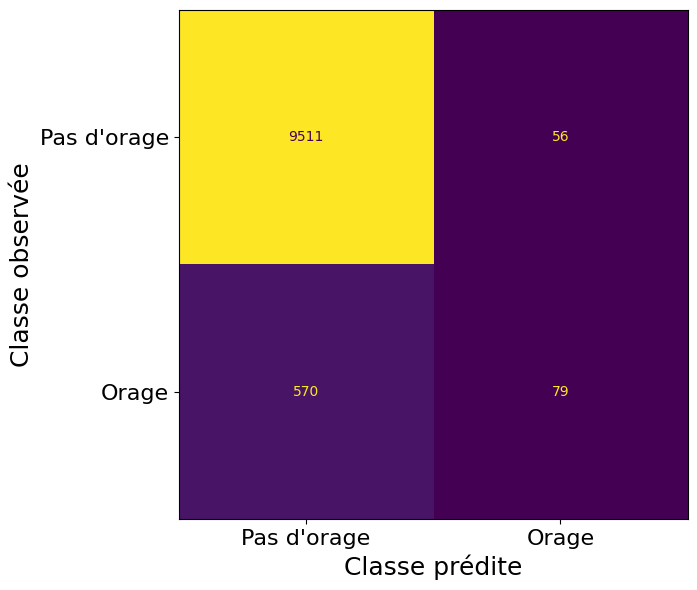

In [16]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Pas d'orage", "Orage"]
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, values_format="d", colorbar=False)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlabel("Classe prédite", fontsize=18)
plt.ylabel("Classe observée", fontsize=18)
plt.grid(False)

plt.tight_layout()
plt.show()

La matrice contient quatre types de résultats :

- **TN** : pas d'orage observé et pas d'orage prédit ;
- **FP** : pas d'orage observé mais orage prédit ;
- **FN** : orage observé mais non détecté ;
- **TP** : orage observé et correctement détecté.

## 10. Calculer les principales métriques

In [17]:
def classification_metrics(y_true, y_pred, y_prob):
    return pd.Series({
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Average Precision": average_precision_score(y_true, y_prob)
    })

metrics_default = classification_metrics(y_test, y_pred, y_prob)
metrics_default.to_frame("Valeur").round(4)

,Valeur
Accuracy,0.9387
Precision,0.5852
Recall,0.1217
F1-score,0.2015
ROC-AUC,0.8617
Average Precision,0.3724


### Accuracy


$Accuracy = \frac{TP + TN}{TP + TN + FP + FN}$


### Precision


$Precision = \frac{TP}{TP + FP}$


Parmi les orages prédits, quelle proportion correspond réellement à des orages ?

### Recall


$Recall = \frac{TP}{TP + FN}$


Parmi les orages réellement observés, quelle proportion est détectée ?

### F1-score


$F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}$


Le F1-score combine precision et recall.

### ROC-AUC

Le ROC-AUC mesure la capacité du modèle à séparer les deux classes, indépendamment d'un seuil unique.

### Average Precision

Average Precision résume la courbe Precision–Recall et est particulièrement utile lorsque la classe positive est rare.

## 11. Pourquoi l'accuracy seule ne suffit pas ?

In [18]:
always_zero = np.zeros_like(y_test)

baseline_accuracy = accuracy_score(y_test, always_zero)
baseline_recall = recall_score(y_test, always_zero, zero_division=0)

print(f"Accuracy si l'on prédit toujours 0 : {baseline_accuracy:.4f}")
print(f"Recall si l'on prédit toujours 0   : {baseline_recall:.4f}")

Accuracy si l'on prédit toujours 0 : 0.9365
Recall si l'on prédit toujours 0   : 0.0000


Un modèle naïf peut obtenir une accuracy élevée simplement parce que la majorité des observations sont des `0`.

Pour la détection d'orages, le recall est important lorsque l'on souhaite limiter le nombre d'orages manqués.

## 12. Effet du seuil de classification

In [19]:
thresholds = [0.10, 0.20, 0.30, 0.50, 0.70]

rows = []

for threshold in thresholds:
    pred = (y_prob >= threshold).astype(int)

    rows.append({
        "Seuil": threshold,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "Nombre prédit positif": pred.sum()
    })

threshold_results = pd.DataFrame(rows)
threshold_results.round(4)

,Seuil,Accuracy,Precision,Recall,F1-score,Nombre prédit positif
0,0.1,0.8454,0.2476,0.7026,0.3661,1842
1,0.2,0.9172,0.3779,0.4700,0.4190,807
2,0.3,0.9356,0.4893,0.3159,0.3839,419
3,0.5,0.9387,0.5852,0.1217,0.2015,135
4,0.7,0.9380,0.7500,0.0370,0.0705,32


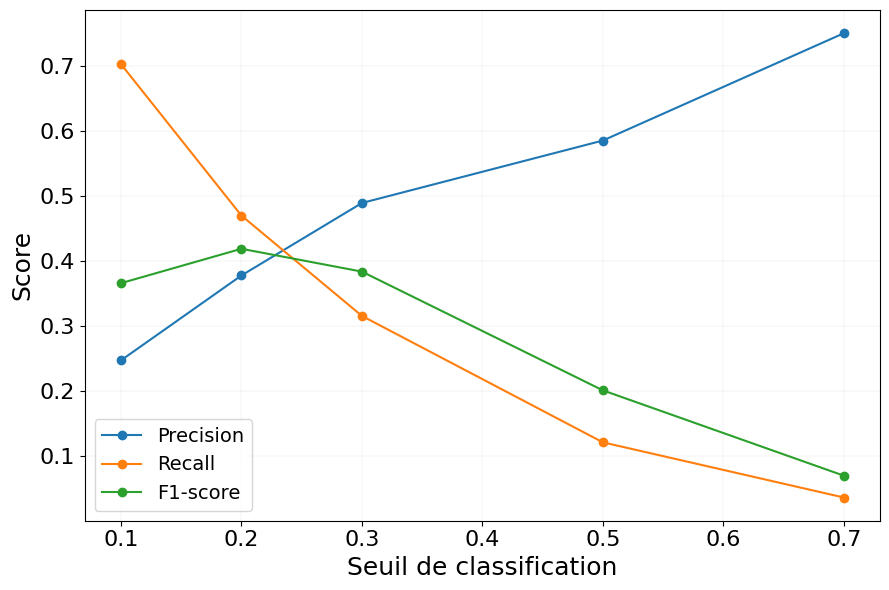

In [20]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(threshold_results["Seuil"], threshold_results["Precision"], marker="o", label="Precision")
ax.plot(threshold_results["Seuil"], threshold_results["Recall"], marker="o", label="Recall")
ax.plot(threshold_results["Seuil"], threshold_results["F1-score"], marker="o", label="F1-score")

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("Seuil de classification", fontsize=18)
plt.ylabel("Score", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.tight_layout()
plt.show()

Lorsque le seuil diminue :

- davantage d'observations sont classées comme orages ;
- le recall augmente généralement ;
- le nombre de faux positifs augmente souvent ;
- la precision peut diminuer.

Le choix du seuil dépend donc de l'application.

## 13. Courbe ROC et AUC

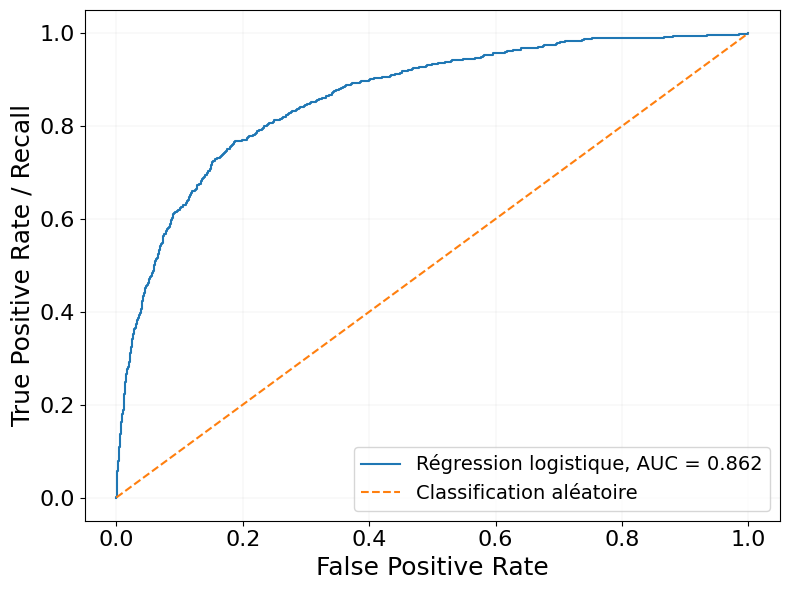

In [21]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(fpr, tpr, label=f"Régression logistique, AUC = {auc:.3f}")
ax.plot([0, 1], [0, 1], linestyle="--", label="Classification aléatoire")

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("False Positive Rate", fontsize=18)
plt.ylabel("True Positive Rate / Recall", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.tight_layout()
plt.show()

Une AUC de `0.5` correspond à un classement aléatoire.

Plus l'AUC se rapproche de `1`, meilleure est la capacité du modèle à distinguer les deux classes.

## 14. Courbe Precision–Recall

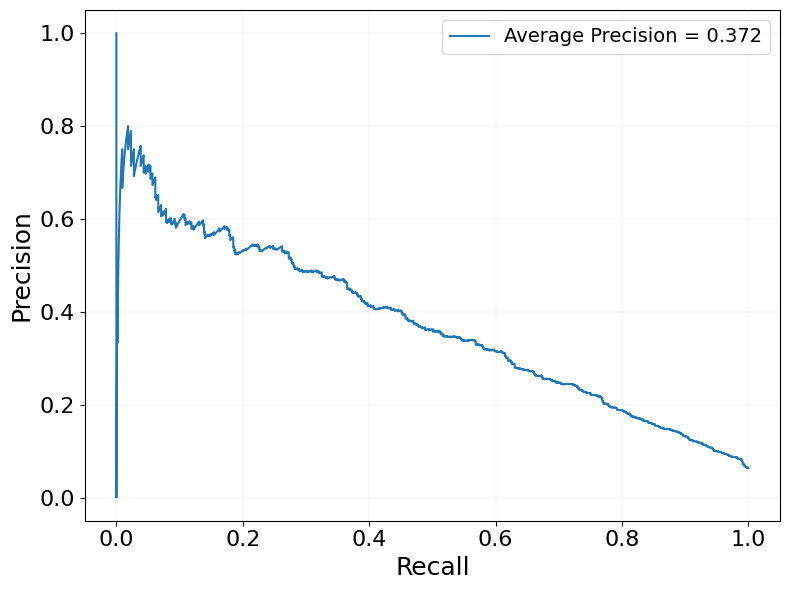

In [22]:
precision_values, recall_values, pr_thresholds = precision_recall_curve(y_test, y_prob)
ap = average_precision_score(y_test, y_prob)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(recall_values, precision_values, label=f"Average Precision = {ap:.3f}")

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=14)

plt.xlabel("Recall", fontsize=18)
plt.ylabel("Precision", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.tight_layout()
plt.show()

La courbe Precision–Recall est particulièrement utile lorsque la classe positive est rare.

Elle permet d'étudier directement le compromis entre détection des orages et fausses alertes.

## 15. Tenir compte du déséquilibre des classes

In [23]:
balanced_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

balanced_model.fit(X_train, y_train)

y_prob_balanced = balanced_model.predict_proba(X_test)[:, 1]
y_pred_balanced = (y_prob_balanced >= 0.5).astype(int)

comparison = pd.concat(
    [
        classification_metrics(y_test, y_pred, y_prob).rename("Sans pondération"),
        classification_metrics(y_test, y_pred_balanced, y_prob_balanced).rename("class_weight='balanced'")
    ],
    axis=1
)

comparison.round(4)

,Sans pondération,class_weight='balanced'
Accuracy,0.9387,0.7830
Precision,0.5852,0.2008
Recall,0.1217,0.8105
F1-score,0.2015,0.3218
ROC-AUC,0.8617,0.8655
Average Precision,0.3724,0.3421


`class_weight="balanced"` donne davantage d'importance à la classe minoritaire pendant l'entraînement.

Cela peut augmenter le recall, mais aussi augmenter le nombre de faux positifs.

## 16. Interpréter les coefficients

In [24]:
coefficients = model.named_steps["logistic"].coef_[0]

coef_df = pd.DataFrame({
    "Variable": features,
    "Coefficient": coefficients
}).sort_values("Coefficient")

coef_df

,Variable,Coefficient
9,distance,-1.596291
5,lat,-0.470047
6,lon,-0.288446
1,month,-0.058553
0,year,-0.051066
4,minute,-0.012644
2,day,0.084123
3,hour,0.088569
8,size,0.347711
7,intensity,0.897416


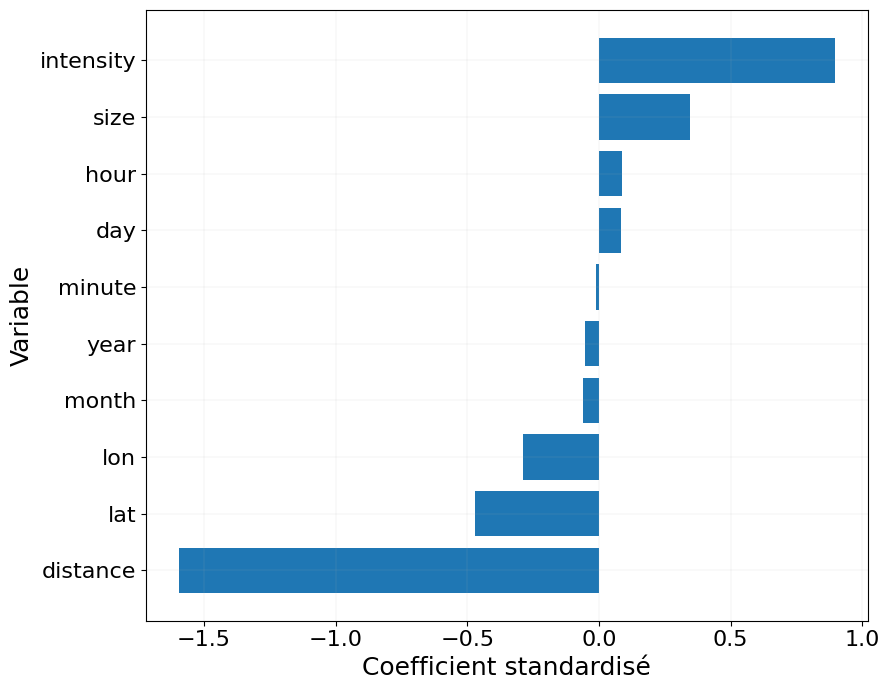

In [25]:
fig, ax = plt.subplots(figsize=(9, 7))

ax.barh(coef_df["Variable"], coef_df["Coefficient"])

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.xlabel("Coefficient standardisé", fontsize=18)
plt.ylabel("Variable", fontsize=18)
plt.grid(True, linewidth=0.1)

plt.tight_layout()
plt.show()

Comme les variables ont été standardisées :

- un coefficient positif augmente le log-odds d'orage ;
- un coefficient négatif le diminue ;
- une valeur absolue plus grande indique une association plus forte dans ce modèle.

Cela ne signifie pas qu'il existe une relation causale.

## 17. Résumé

Dans ce notebook :

1. la régression logistique produit une probabilité ;
2. un seuil transforme cette probabilité en classe ;
3. la matrice de confusion distingue TP, TN, FP et FN ;
4. l'accuracy peut être trompeuse avec des classes déséquilibrées ;
5. precision et recall répondent à des questions différentes ;
6. le F1-score combine precision et recall ;
7. ROC-AUC évalue la capacité de discrimination ;
8. la courbe Precision–Recall est utile lorsque la classe positive est rare ;
9. `class_weight="balanced"` permet de donner davantage de poids à la classe minoritaire ;
10. le seuil doit être choisi selon l'objectif de l'application.

## 18. Exercices

### Exercice 1

Testez les seuils `0.15`, `0.25`, `0.35` et `0.45`.

Pour chaque seuil, calculez :

- precision ;
- recall ;
- F1-score ;
- nombre de faux positifs ;
- nombre de faux négatifs.

### Exercice 2

Retirez une variable explicative et comparez les performances.

### Exercice 3

Utilisez seulement :

`lat`, `lon`, `intensity`, `size`, `distance`

et comparez avec le modèle utilisant également les variables temporelles.

### Exercice 4

Comparez le modèle standard et le modèle avec `class_weight="balanced"`.

Discutez le compromis entre détection des orages et fausses alertes.